# Run 5c: the excess sky in needlets, no positions assumed

Run 5's data ([run5_needlet_sky.ipynb](run5_needlet_sky.ipynb)): run 2's smooth Galaxy plus four bright patches (LMC,
SMC, Sgr dSph, bar end; 20%, 8%, 12%, 12% of the Galaxy's flux), same noise realisation as run 2. Same WDM data
settings and Gamma likelihood as runs 1–5a. Three models of the power modulation are compared on the same pixels:

| | modulation model | sky knowledge | free sky parameters | sampler |
|---|---|---|---|---|
| **atoms** (run 5) | $\ln P_c(t)$ = level + Gaussian atoms, per channel | none | K, atoms | eryn RJMCMC |
| **5a** ([patch_fit.py](patch_fit.py)) | $T_{c,\mathrm{gal}} + \sum_i F_i T_{c,i}$ | Galaxy shape **and patch positions** | 4 fluxes | NUTS |
| **5c** ([needlet_fit.py](needlet_fit.py)) | $T_{c,\mathrm{gal}} + \sum_{jk} \beta_{jk} T_{c,jk}$ | Galaxy shape only | 241 needlet coefficients | NUTS on the 11 visible directions + exact prior draws |

5c: needlets of bands j = −1, 1, 2 (ℓ = 0; 2–3; 3–7) on the response grid (nside 32), prior
$\beta_{jk} \sim N(0, s_j^2)$ with $s_j$ the rms of the smooth Galaxy's own needlet coefficients in band j. The
likelihood depends on $z = \beta/s$ only through $Mz$, $M = T\,\mathrm{diag}(s)$, whose rank is 11 (singular values
below $10^{-6}$ of the largest dropped; the next is $3\times10^{-7}$). NUTS samples those 11 coordinates and the 7
spectral parameters; the other 230 directions are drawn from their prior. That is the exact posterior of the
241-coefficient model. A second run with the prior sd ×3 checks the prior's influence.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
import jax
import jax.numpy as jnp

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
HERE = ROOT / 'data' / 'wavelet_injection'
sys.path.insert(0, str(HERE))
import injection as I
import patch_fit as PF
import needlet_fit as NF
from bahamas.wavelet.model import DAY
from bahamas.wavelet.sampler import modulation_draws, _sampled

OUT = HERE / 'outputs' / 'run5'
OUT5C = OUT / '5c'
CH = ['A', 'E']
C_TRUTH, C_AT, C_AT_L, C_PF, C_PF_L, C_NL, C_NL_L, C_MUTED = ('#0b0b0b', '#2a78d6', '#86b6ef', '#eb6834', '#f5b48f',
                                                             '#1baf7a', '#8fdcbc', '#52514e')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e4e3df', 'axes.spines.top': False,
                     'axes.spines.right': False})

data, inj = I.load_or_simulate('patches', 'run5')
like_at, post_at = I.build_posterior(data)
nf = NF.NeedletFit(data)
r_at = dict(np.load(OUT / 'chains.npz', allow_pickle=True))
r_pf = dict(np.load(OUT / '5a' / 'chains.npz', allow_pickle=True))
r_nl = dict(np.load(OUT5C / 'chains.npz', allow_pickle=True))
r_n3 = dict(np.load(OUT5C / 'chains_prior3x.npz', allow_pickle=True))
nf3 = NF.NeedletFit(data, prior_scale=3.0)
amp_true = I.true_amp()
truth_src = {p['name']: p['injected'] for s in I.og_sources().values() for p in s}
print(f"K = {nf.K} needlets, r = {nf.r} data-visible directions")
for lab, r in (('atoms', r_at), ('5a', r_pf), ('5c', r_nl), ('5c prior x3', r_n3)):
    print(f"{lab:12s} runtime {float(r['runtime_s']) / 60:5.1f} min")

2026-10-18 16:23:57,436 - BAHAMAS - INFO - Using JAX backend.


2026-10-18 16:23:57,437 - BAHAMAS - INFO - np is from: jax.numpy


K = 241 needlets, r = 11 data-visible directions
atoms        runtime  57.7 min
5a           runtime  56.4 min
5c           runtime  34.2 min
5c prior x3  runtime  46.0 min


## 1. Sampling checks

In [2]:
for lab, r in (('5c', r_nl), ('5c prior x3', r_n3)):
    print(f"{lab}: {int(r['chains'])} chains x {int(r['samples'])} draws, {int(r['divergences'])} divergences, "
          f"mean leapfrog steps {float(r['num_steps_mean']):.0f}, max r_hat {r['r_hat'].max():.3f}, "
          f"min n_eff {r['n_eff'].min():.0f}")
    print(f"   log L: median {np.median(r['log_like']):.1f}, at the truth {float(r['loglike_true']):.1f}")

5c: 4 chains x 2000 draws, 10 divergences, mean leapfrog steps 28, max r_hat 1.002, min n_eff 1881
   log L: median 1118877.7, at the truth 1118876.4
5c prior x3: 4 chains x 2000 draws, 12 divergences, mean leapfrog steps 53, max r_hat 1.003, min n_eff 1072
   log L: median 1118877.5, at the truth 1118876.4


## 2. How many sky directions do the data measure?

Each visible direction $y_i$ has prior N(0, 1). A posterior sd well below 1 means the data, not the prior, set it.
Directions are ordered by singular value (most visible first). Dots: the true excess's coordinate.

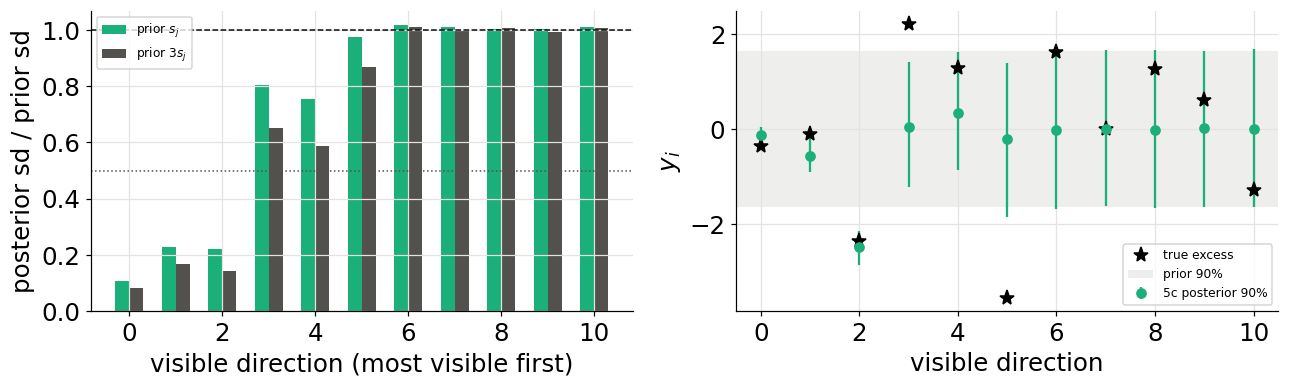

prior s_j: posterior sd / prior sd = [0.11 0.23 0.22 0.8  0.76 0.98 1.02 1.01 1.   1.   1.01];  measured (< 0.5): 3
prior 3 s_j: posterior sd / prior sd = [0.08 0.17 0.14 0.65 0.59 0.87 1.01 1.   1.01 0.99 1.01];  measured (< 0.5): 3
(median - truth) / sd per direction, prior s_j: [ 2.17 -1.99 -0.55 -2.7  -1.26  3.42 -1.61  0.01 -1.29 -0.59  1.26]
posterior sd with prior x3 / with prior x1 (1 = data-dominated, 3 = prior-dominated): [2.33 2.18 1.94 2.42 2.34 2.67 2.98 2.96 3.01 2.97 2.98]


In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
i = np.arange(nf.r)
for r, col, lab, dx in ((r_nl, C_NL, 'prior $s_j$', -0.15), (r_n3, C_MUTED, 'prior $3 s_j$', 0.15)):
    a1.bar(i + dx, r['y_chain'].std(0), width=0.3, color=col, label=lab)
a1.axhline(1, color=C_TRUTH, ls='--', lw=1); a1.axhline(0.5, color=C_MUTED, ls=':', lw=1)
a1.set_xlabel('visible direction (most visible first)'); a1.set_ylabel('posterior sd / prior sd'); a1.legend(fontsize=8)
q = np.percentile(r_nl['y_chain'], [5, 50, 95], axis=0)
a2.errorbar(i, q[1], yerr=[q[1] - q[0], q[2] - q[1]], fmt='o', color=C_NL, label='5c posterior 90%')
a2.plot(i, nf.y_true, 'k*', ms=10, label='true excess')
a2.axhspan(-1.645, 1.645, color='#eeeeec', lw=0, zorder=0, label='prior 90%')
a2.set_xlabel('visible direction'); a2.set_ylabel('$y_i$'); a2.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT5C / 'visible_directions_5c.png', dpi=150); plt.show()

for lab, r in (('prior s_j', r_nl), ('prior 3 s_j', r_n3)):
    sd = r['y_chain'].std(0)
    print(f"{lab}: posterior sd / prior sd = {np.round(sd, 2)};  measured (< 0.5): {int(np.sum(sd < 0.5))}")
z = (np.median(r_nl['y_chain'], 0) - nf.y_true) / r_nl['y_chain'].std(0)
print('(median - truth) / sd per direction, prior s_j:', np.round(z, 2))
# absolute posterior sd in units of the baseline prior: data-dominated directions keep it when the prior widens
ratio = 3 * r_n3['y_chain'].std(0) / r_nl['y_chain'].std(0)
print('posterior sd with prior x3 / with prior x1 (1 = data-dominated, 3 = prior-dominated):', np.round(ratio, 2))

## 3. Total brightness and spectra: atoms vs 5a vs 5c

The 30-day galactic brightness recovered / injected in A and E, per posterior draw, as in
[run5a_known_patches.ipynb](run5a_known_patches.ipynb) §2c: $10^{\mathrm{amp}-\mathrm{amp_{true}}}$ × the
information-weighted ratio of the galactic spectrum to the true one × the recovered $P_c(t)$ over the true one.

In [4]:
t_fine = np.linspace(0, data.Nt * data.Nf * data.dt, 600)
an = np.asarray(nf.like.times)
win = (t_fine >= an[0]) & (t_fine <= an[-1])
T_fine = nf.templates(t_fine)
P_true = T_fine[..., 0] + T_fine[..., 1:] @ nf.flux_true                                     # (2, nt)
P_gal_true = T_fine[..., 0]
MV_fine = nf.MV_at(t_fine)

def spectral_ratio(post, chain, names):
    theta0 = np.array([p.value for p in _sampled(post.psd_params)], float)
    th = np.array(chain, float); th[:, names.index('amp')] = theta0[names.index('amp')]
    Sg0, Sn0, _ = post.spectra(jnp.asarray(theta0)); Sg0, Sn0 = np.asarray(Sg0), np.asarray(Sn0)
    ok = Sg0 > 1e-3 * Sg0.max()
    W = np.stack([np.where(ok, np.asarray(post.like.nu) * (Sg0 / (Sg0 + Sn0[c])) ** 2, 0.) for c in (0, 1)])
    W /= W.sum(1, keepdims=True)
    Sg = np.asarray(jax.jit(jax.vmap(lambda t: post.spectra(t)[0]))(jnp.asarray(th)))
    return np.where(ok, Sg / np.where(ok, Sg0, 1.), 0.) @ W.T

rng = np.random.default_rng(0)
def brightness_sky(r, P_of):
    i = rng.choice(len(r['psd_chain']), 1000, replace=False)
    names = list(r['psd_names'])
    amp = r['psd_chain'][i, names.index('amp')]
    P = P_of(i)
    return i, 10 ** (amp - amp_true)[:, None, None] * P * spectral_ratio(nf.post, r['psd_chain'][i], names)[:, :, None] / P_true

i_pf, B_pf = brightness_sky(r_pf, lambda i: np.stack([P_gal_true + T_fine[..., 1:] @ f for f in r_pf['flux_chain'][i]]))
i_nl, B_nl = brightness_sky(r_nl, lambda i: np.stack([P_gal_true + MV_fine @ y for y in r_nl['y_chain'][i]]))
names_at = [str(n).split(':')[-1] for n in r_at['psd_names']]
idx_at = np.random.default_rng(0).choice(len(r_at['psd_chain']), size=1000, replace=False)
P_at = 10 ** (inj.amp_ref - amp_true) * modulation_draws(post_at, r_at, t_fine, nsamples=1000, seed=0)
th_at = r_at['psd_chain'][idx_at]
B_at = P_at * spectral_ratio(post_at, th_at, names_at)[:, :, None] / P_true

shared = ['alpha', 'fknee', 'fr1', 'fr2', 'A', 'P']
mean_b = lambda B: (B[:, :, win] * P_true[None, :, win]).mean(-1) / P_true[None, :, win].mean(-1)
tabs = {'atoms': np.column_stack([th_at[:, [names_at.index(k) for k in shared]], mean_b(B_at)]),
        '5a': np.column_stack([r_pf['psd_chain'][i_pf][:, [list(r_pf['psd_names']).index(k) for k in shared]], mean_b(B_pf)]),
        '5c': np.column_stack([r_nl['psd_chain'][i_nl][:, [list(r_nl['psd_names']).index(k) for k in shared]], mean_b(B_nl)])}
labels = shared + ['brightness A', 'brightness E']
truths = [truth_src[k] for k in shared] + [1.0, 1.0]
print(f"{'param':13s} {'truth':>8s} | " + ' | '.join(f'{m:>6s}: median  90% width' for m in tabs))
for j, k in enumerate(labels):
    row = []
    for m, X in tabs.items():
        q = np.percentile(X[:, j], [5, 50, 95]); row.append(f'{q[1]:14.4f} {q[2] - q[0]:11.4f}')
    print(f"{k:13s} {truths[j]:8.3f} | " + ' | '.join(row))

param            truth |  atoms: median  90% width |     5a: median  90% width |     5c: median  90% width
alpha            1.800 |         1.8333      0.1753 |         1.8449      0.1767 |         1.8419      0.1738
fknee           -2.177 |        -2.1783      0.0045 |        -2.1781      0.0048 |        -2.1781      0.0046
fr1             -2.429 |        -2.4198      0.0225 |        -2.4180      0.0215 |        -2.4186      0.0221
fr2             -3.488 |        -3.5230      0.1495 |        -3.5331      0.1495 |        -3.5324      0.1526
A                2.400 |         2.4603      0.1455 |         2.4643      0.1277 |         2.4624      0.1313
P                7.900 |         7.9059      0.0398 |         7.9051      0.0409 |         7.9046      0.0403
brightness A     1.000 |         1.0150      0.0317 |         1.0144      0.0315 |         1.0111      0.0336
brightness E     1.000 |         0.9899      0.0317 |         0.9878      0.0321 |         0.9922      0.0323


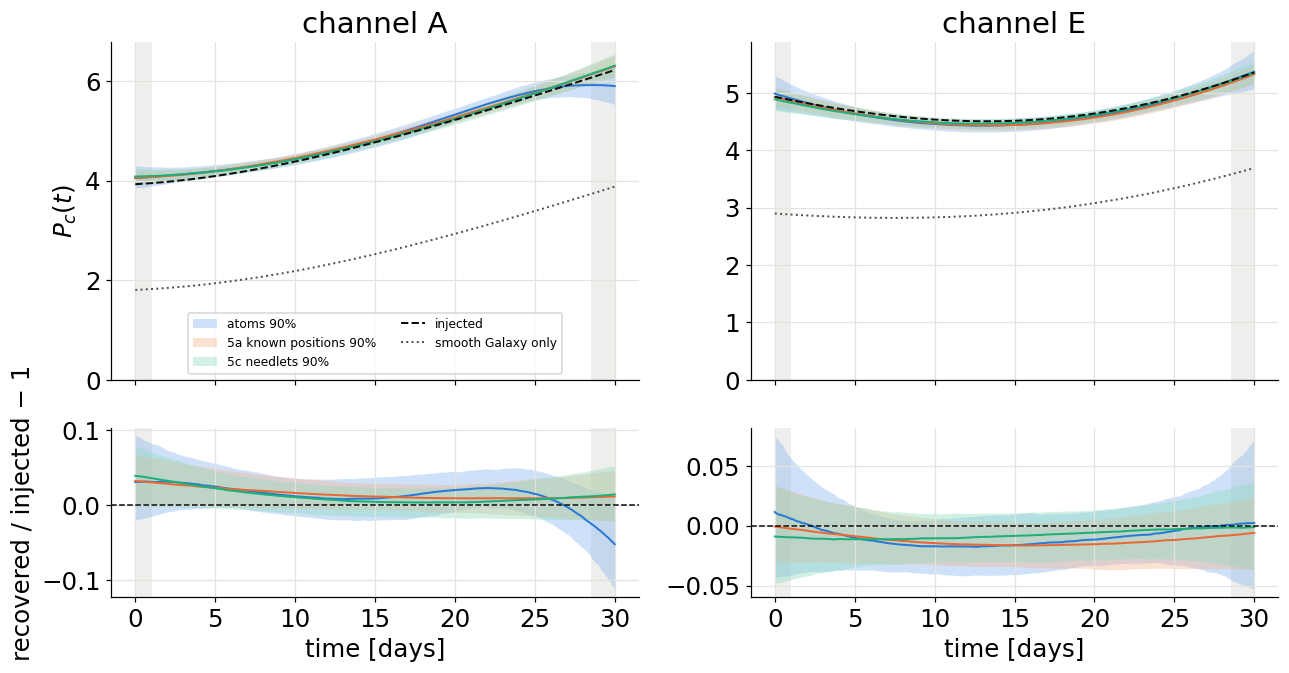

A atoms: median |rec/inj - 1| 0.017, median 90% width 0.056, truth inside 90% band 100%
A 5a   : median |rec/inj - 1| 0.012, median 90% width 0.042, truth inside 90% band 92%
A 5c   : median |rec/inj - 1| 0.008, median 90% width 0.043, truth inside 90% band 100%
E atoms: median |rec/inj - 1| 0.012, median 90% width 0.049, truth inside 90% band 100%
E 5a   : median |rec/inj - 1| 0.014, median 90% width 0.043, truth inside 90% band 100%
E 5c   : median |rec/inj - 1| 0.009, median 90% width 0.043, truth inside 90% band 100%


In [5]:
td = t_fine / DAY
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for c, ch in enumerate(CH):
    ax, axr = axes[:, c]
    for B, cl, cd, lab in ((B_at, C_AT_L, C_AT, 'atoms'), (B_pf, C_PF_L, C_PF, '5a known positions'),
                           (B_nl, C_NL_L, C_NL, '5c needlets')):
        q = np.percentile(B[:, c] * P_true[c], [5, 50, 95], axis=0)
        ax.fill_between(td, q[0], q[2], color=cl, alpha=0.4, lw=0, label=f'{lab} 90%')
        ax.plot(td, q[1], color=cd, lw=1.3)
        r = np.percentile(B[:, c], [5, 50, 95], axis=0)
        axr.fill_between(td, r[0] - 1, r[2] - 1, color=cl, alpha=0.4, lw=0); axr.plot(td, r[1] - 1, color=cd, lw=1.3)
    ax.plot(td, P_true[c], color=C_TRUTH, ls='--', lw=1.3, label='injected')
    ax.plot(td, P_gal_true[c], color=C_MUTED, ls=':', lw=1.3, label='smooth Galaxy only')
    axr.axhline(0, color=C_TRUTH, ls='--', lw=1)
    for a in (ax, axr):
        a.axvspan(td[0], an[0] / DAY, color='#eeeeec', lw=0, zorder=0); a.axvspan(an[-1] / DAY, td[-1], color='#eeeeec', lw=0, zorder=0)
    ax.set_title(f'channel {ch}'); ax.set_ylim(0, None); axr.set_xlabel('time [days]')
axes[0, 0].set_ylabel('$P_c(t)$'); axes[1, 0].set_ylabel('recovered / injected − 1'); axes[0, 0].legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(OUT5C / 'modulation_5c.png', dpi=150); plt.show()
for c, ch in enumerate(CH):
    for B, lab in ((B_at, 'atoms'), (B_pf, '5a   '), (B_nl, '5c   ')):
        r = np.percentile(B[:, c][:, win], [5, 50, 95], axis=0)
        print(f"{ch} {lab}: median |rec/inj - 1| {np.median(np.abs(r[1] - 1)):.3f}, median 90% width "
              f"{np.median(r[2] - r[0]):.3f}, truth inside 90% band {100 * np.mean((r[0] <= 1) & (1 <= r[2])):.0f}%")

## 4. How much excess?

Total excess flux: in 5c it is the monopole alone, $\sqrt{4\pi}\,\beta_{-1}$ (bands j ≥ 1 have no ℓ = 0); in 5a the
sum of the four fluxes. Truth 0.52. Below: the excess modulation $P_c(t) - T_{c,\mathrm{gal}}(t)$ relative to the
smooth Galaxy, which the data see directly (amp held at each draw's value is not applied here: this is the sky
model's own excess).

total excess flux 5c          : median 0.167, 90% [-0.159, 0.532], sd 0.212  (truth 0.52)
total excess flux 5c prior x3 : median 0.728, 90% [-0.184, 1.642], sd 0.559  (truth 0.52)
total excess flux 5a          : median 0.682, 90% [0.510, 0.917], sd 0.123  (truth 0.52)


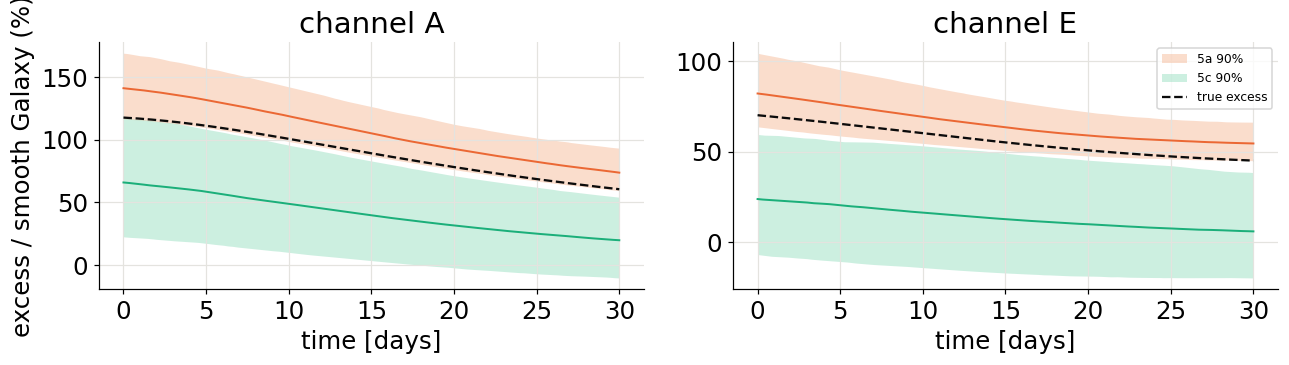

In [6]:
i_m = list(nf.band).index(-1)
tot = {'5c': np.sqrt(4 * np.pi) * r_nl['beta_draws'][:, i_m], '5c prior x3': np.sqrt(4 * np.pi) * r_n3['beta_draws'][:, i_m],
       '5a': r_pf['flux_chain'].sum(1)}
for k, v in tot.items():
    q = np.percentile(v, [5, 50, 95])
    print(f"total excess flux {k:12s}: median {q[1]:.3f}, 90% [{q[0]:.3f}, {q[2]:.3f}], sd {v.std():.3f}  (truth 0.52)")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ex_true = T_fine[..., 1:] @ nf.flux_true
for c, ax in enumerate(axes):
    for draws, cl, cd, lab in ((np.stack([T_fine[c, :, 1:] @ f for f in r_pf['flux_chain'][i_pf]]), C_PF_L, C_PF, '5a'),
                               (np.stack([MV_fine[c] @ y for y in r_nl['y_chain'][i_nl]]), C_NL_L, C_NL, '5c')):
        q = np.percentile(100 * draws / P_gal_true[c], [5, 50, 95], axis=0)
        ax.fill_between(td, q[0], q[2], color=cl, alpha=0.45, lw=0, label=f'{lab} 90%'); ax.plot(td, q[1], color=cd, lw=1.3)
    ax.plot(td, 100 * ex_true[c] / P_gal_true[c], color=C_TRUTH, ls='--', label='true excess')
    ax.set_title(f'channel {CH[c]}'); ax.set_xlabel('time [days]')
axes[0].set_ylabel('excess / smooth Galaxy (%)'); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT5C / 'excess_5c_vs_5a.png', dpi=150); plt.show()

## 5. Where is the excess? The maps

Top: the true excess, and its ℓ = 0, 2, 4 part (all the data can ever see). Bottom: the 5c posterior mean, its
posterior sd, and mean / sd. Galactic coordinates, flux per pixel (nside 32).

corr(posterior mean, true excess)            = 0.07
corr(posterior mean l=0,2,4, true l=0,2,4)    = 0.44
max |mean / sd| over the sky                  = 1.08


prior x3: corr visible 0.69, max |mean/sd| 0.93


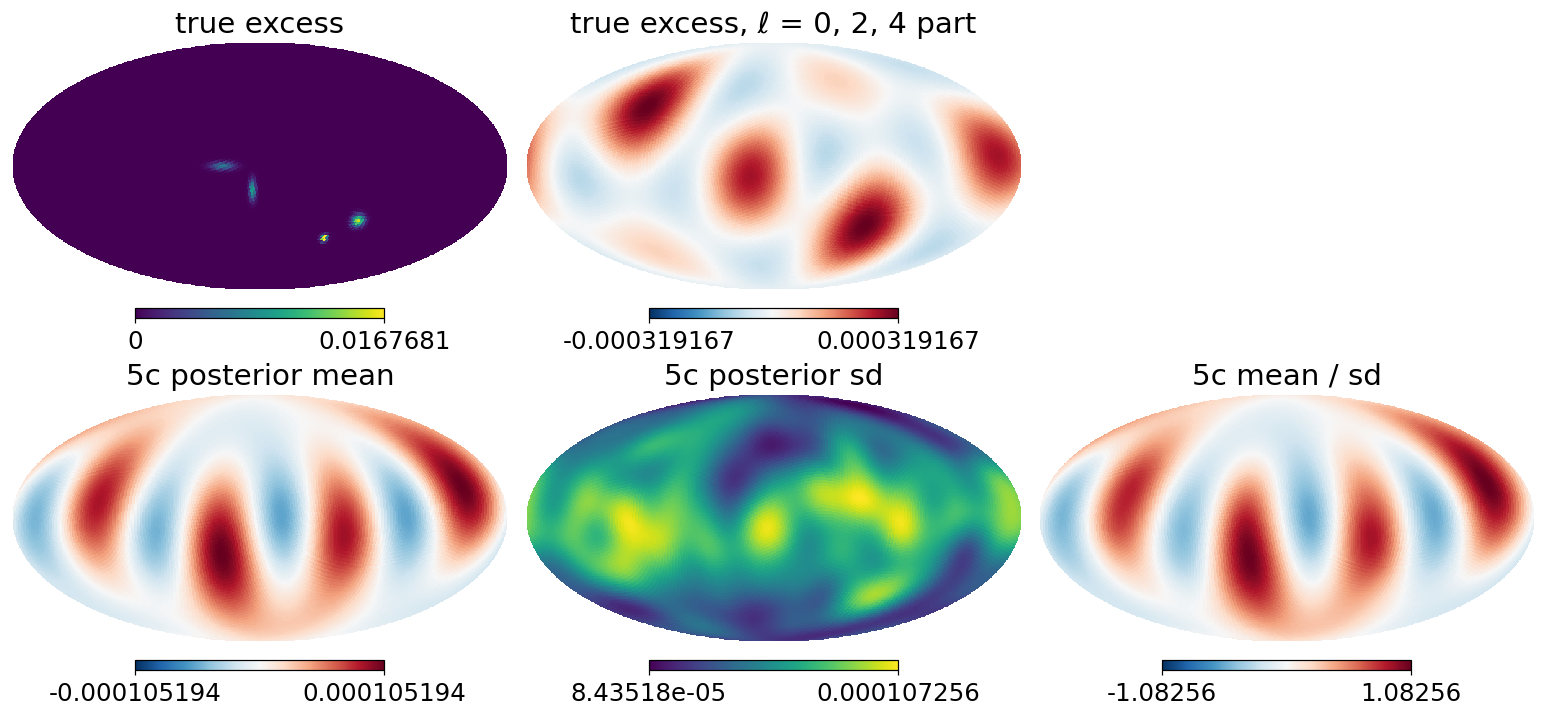

In [7]:
def maps_from(r, fit, n=1000):
    B = r['beta_draws'][:n]
    m = fit.flux_map(B)
    return m.mean(0), m.std(0)
mean_m, sd_m = maps_from(r_nl, nf)
true_ex = nf.excess_map
true_vis = NF.visible_part(true_ex)
mean_vis = NF.visible_part(mean_m)
corr = lambda a, b: float(np.corrcoef(a, b)[0, 1])
print(f"corr(posterior mean, true excess)            = {corr(mean_m, true_ex):.2f}")
print(f"corr(posterior mean l=0,2,4, true l=0,2,4)    = {corr(mean_vis, true_vis):.2f}")
print(f"max |mean / sd| over the sky                  = {np.max(np.abs(mean_m / sd_m)):.2f}")
m3, s3 = maps_from(r_n3, nf3)
print(f"prior x3: corr visible {corr(NF.visible_part(m3), true_vis):.2f}, max |mean/sd| {np.max(np.abs(m3 / s3)):.2f}")
fig = plt.figure(figsize=(14, 6.4))
panels = [(true_ex, 'true excess'), (true_vis, 'true excess, ℓ = 0, 2, 4 part'), (None, None),
          (mean_m, '5c posterior mean'), (sd_m, '5c posterior sd'), (mean_m / sd_m, '5c mean / sd')]
for k, (m, t) in enumerate(panels):
    if m is None:
        continue
    kw = dict(cmap='RdBu_r', min=-np.max(np.abs(m)), max=np.max(np.abs(m))) if k in (1, 3, 5) else dict(cmap='viridis')
    hp.mollview(m, coord=['E', 'G'], title=t, sub=(2, 3, k + 1), fig=fig.number, cbar=True, notext=True, **kw)
fig.savefig(OUT5C / 'maps_5c.png', dpi=130, bbox_inches='tight'); plt.show()

## 6. Summary

* **Sampling.** The 241-coefficient model has 11 data-visible directions (singular values below $10^{-6}$ of the
  largest dropped). NUTS on those plus the 7 spectral parameters, the rest drawn exactly from the prior: 4 × 2000
  draws, 10 divergent transitions (0.1%), $\hat R \le 1.002$, $n_\mathrm{eff} \ge 1900$. Sampling the excess as
  $q = 10^{\mathrm{amp}-\mathrm{amp}_0}\,y$ was needed: in $(\mathrm{amp}, y)$ the two trade along a curved ridge
  (correlation 0.985) and the first run had 7% divergences (kept as `chains_v1_ycoords.npz`).
* **Total brightness: as good as the other two models.** 30-day brightness recovered / injected 1.011 (A) and 0.992
  (E), 90% widths 3.4% and 3.2%, against 3.2% for atoms and for 5a; the truth is inside the 90% band at all
  analysed times in both channels. Spectral parameters agree across all three models.
* **Only 3 of 11 visible directions are measured** (posterior sd below half the prior), and none is set by the data
  alone: widening the prior 3× widens even those by 1.9–2.4× (3 would be pure prior).
* **How much excess: not measured.** Total excess flux 0.17 ± 0.21 (truth 0.52); with the prior ×3, 0.73 ± 0.56.
  The Galaxy's amplitude absorbs it: amp comes out +0.12 dex (×1.33) high, anticorrelated with the excess flux
  (−0.72). With the Galaxy shape fixed but amp free, an excess spread over needlets has nearly the Galaxy's own
  time profile, so the data fix their sum and the prior sets the split. 5a, with the positions given, measures the
  total excess flux at 0.68 ± 0.12.
* **Where: not located.** The posterior mean's ℓ = 0, 2, 4 part correlates 0.44 with the true excess's (0.69 with
  the prior ×3), but nowhere exceeds 1.1σ. This matches the noise-free Wiener filter of stage 1
  (`needlet_patches`): correlation 0.50, max |mean/sd| 0.5–1.4.
* **The prior is too narrow for compact patches.** Scaled to the smooth Galaxy's needlet rms, it puts the true
  excess at up to 3.5σ in single directions (compact patches carry more ℓ = 2, 4 power than a smooth Galaxy), so
  unmeasured directions shrink to zero; direction 5 ends 3.4σ from the truth for that reason alone.

**Conclusion.** In 30 days a position-free sky model recovers the total galactic modulation as well as the atoms
or the known-position templates, but cannot separate an excess from the Galaxy's brightness, nor place it. What
5a measures about the patches comes from knowing where they are. A year of data, with the response turning through
360°, is the next test.